In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_excel(
    "blossom.xlsx",
    sheet_name="Station Dataset"
)

df.head()
#Three station-level CSV datasets were integrated using Microsoft Excel.

,station_id,location,jma_station_id,01_02_station_elevations.latitude,01_02_station_elevations.longitude,01_02_station_elevations.elevation_m,01_03_cherry_species.cherry_species
0,401,Wakkanai,s47401,45.415000,141.678333,2.5,Ezo-yamazakura
1,406,Rumoi,s47406,43.945000,141.631667,23.6,Ezo-yamazakura
2,407,Asahikawa,s47407,43.756667,142.371667,119.8,Ezo-yamazakura
3,409,Abashiri,s47409,44.016667,144.278333,37.6,Ezo-yamazakura
4,412,Sapporo,s47412,43.060000,141.328333,17.4,Somei-yoshino


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
#Dataset dimensions

Rows: 102
Columns: 7


In [5]:
print(df.columns.tolist())
#Column names

['station_id', 'location', 'jma_station_id', '01_02_station_elevations.latitude', '01_02_station_elevations.longitude', '01_02_station_elevations.elevation_m', '01_03_cherry_species.cherry_species']


In [6]:
df.info()
#Data types and non-null counts

<class 'pandas.DataFrame'>
RangeIndex: 102 entries, 0 to 101
Data columns (total 7 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   station_id                            102 non-null    int64  
 1   location                              102 non-null    str    
 2   jma_station_id                        102 non-null    str    
 3   01_02_station_elevations.latitude     102 non-null    float64
 4   01_02_station_elevations.longitude    102 non-null    float64
 5   01_02_station_elevations.elevation_m  102 non-null    float64
 6   01_03_cherry_species.cherry_species   102 non-null    str    
dtypes: float64(3), int64(1), str(3)
memory usage: 8.3 KB


In [9]:
numeric_cols = [
    "01_02_station_elevations.latitude",
    "01_02_station_elevations.longitude",
    "01_02_station_elevations.elevation_m"
]

df[numeric_cols].describe().T.round(2)
#Numerical summary

,count,mean,std,min,25%,50%,75%,max
01_02_station_elevations.latitude,102.0,35.77,4.63,24.34,33.98,35.45,37.99,45.42
01_02_station_elevations.longitude,102.0,136.34,4.98,123.01,132.85,136.93,140.29,145.58
01_02_station_elevations.elevation_m,102.0,56.06,110.77,0.50,5.50,21.55,39.70,610.00


In [10]:
categorical_cols = [
    "location",
    "jma_station_id",
    "01_03_cherry_species.cherry_species"
]

df[categorical_cols].describe().T
#Categorical summary

,count,unique,top,freq
location,102,102,Wakkanai,1
jma_station_id,102,102,s47401,1
01_03_cherry_species.cherry_species,102,4,Somei-yoshino,82


In [14]:
df.dtypes
#data type

station_id                                int64
location                                    str
jma_station_id                              str
01_02_station_elevations.latitude       float64
01_02_station_elevations.longitude      float64
01_02_station_elevations.elevation_m    float64
01_03_cherry_species.cherry_species         str
dtype: object

In [31]:
df_clean = df.copy()

print("Missing values:")
print(df_clean.isnull().sum())

print("\nDuplicate rows:", df_clean.duplicated().sum())

print("Duplicate Station IDs:",
      df_clean["station_id"].duplicated().sum())

print("Duplicate JMA IDs:",
      df_clean["jma_station_id"].duplicated().sum())
#Missing values and duplicate identifiers

Missing values:
station_id                              0
location                                0
jma_station_id                          0
01_02_station_elevations.latitude       0
01_02_station_elevations.longitude      0
01_02_station_elevations.elevation_m    0
01_03_cherry_species.cherry_species     0
dtype: int64

Duplicate rows: 0
Duplicate Station IDs: 0
Duplicate JMA IDs: 0


In [32]:
lat = df_clean["01_02_station_elevations.latitude"]
lon = df_clean["01_02_station_elevations.longitude"]

print("Invalid latitude:", (~lat.between(-90, 90)).sum())
print("Invalid longitude:", (~lon.between(-180, 180)).sum())
#Validating geographic coordinates

Invalid latitude: 0
Invalid longitude: 0


In [33]:
species = "01_03_cherry_species.cherry_species"

print(df_clean[species].value_counts(dropna=False))
#Checking categorical consistency

01_03_cherry_species.cherry_species
Somei-yoshino      82
Ezo-yamazakura     10
Hikan-zakura        9
Chishima-zakura     1
Name: count, dtype: int64


In [34]:
quality_report = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Columns",
        "Missing Values",
        "Duplicate Rows",
        "Duplicate Station IDs",
        "Duplicate JMA IDs",
        "Invalid Latitude",
        "Invalid Longitude"
    ],
    "Result": [
        len(df_clean),
        len(df_clean.columns),
        df_clean.isna().sum().sum(),
        df_clean.duplicated().sum(),
        df_clean["station_id"].duplicated().sum(),
        df_clean["jma_station_id"].duplicated().sum(),
        (~lat.between(-90, 90)).sum(),
        (~lon.between(-180, 180)).sum()
    ]
})

display(quality_report)

,Metric,Result
0,Total Records,102
1,Total Columns,7
2,Missing Values,0
3,Duplicate Rows,0
4,Duplicate Station IDs,0
5,Duplicate JMA IDs,0
6,Invalid Latitude,0
7,Invalid Longitude,0


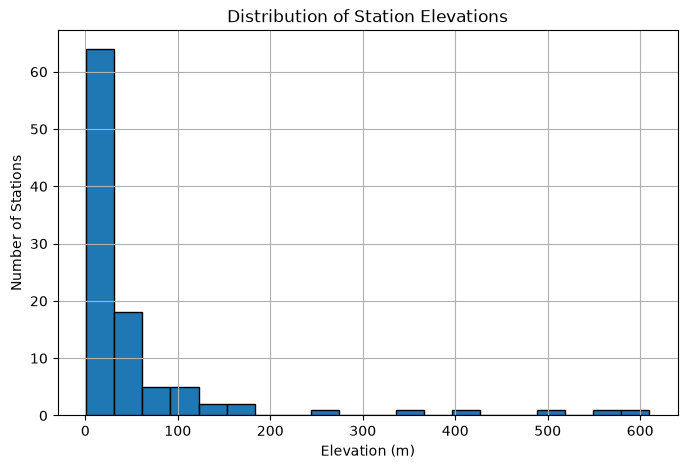

In [20]:
import matplotlib.pyplot as plt

df_clean["01_02_station_elevations.elevation_m"].hist(
    bins=20,
    figsize=(8, 5),
    edgecolor="black"
)

plt.title("Distribution of Station Elevations")
plt.xlabel("Elevation (m)")
plt.ylabel("Number of Stations")
plt.show()
#Elevation distribution

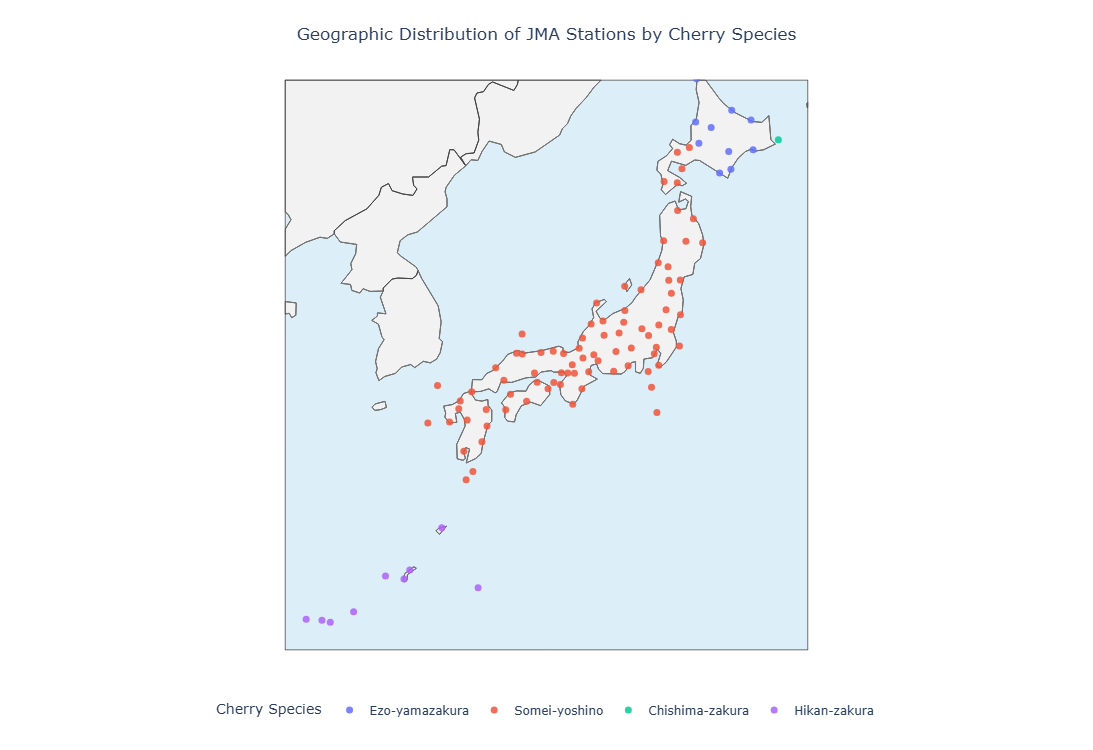

In [30]:
import plotly.express as px

fig = px.scatter_geo(
    df_clean,
    lat="01_02_station_elevations.latitude",
    lon="01_02_station_elevations.longitude",
    hover_name="location",
    color="01_03_cherry_species.cherry_species",
    projection="mercator",
    title="Geographic Distribution of JMA Observation Stations",
    labels={
        "01_03_cherry_species.cherry_species": "Cherry Species"
    }
)

fig.update_geos(
    lonaxis_range=[122, 147],
    lataxis_range=[24, 46],
    showland=True,
    landcolor="#F2F2F2",
    showocean=True,
    oceancolor="#DCEEF8",
    showcountries=True,
    coastlinecolor="#777777",
    showcoastlines=True
)

fig.update_traces(
    marker=dict(size=7, opacity=0.85)
)

fig.update_layout(
    width=950,
    height=650,
    legend_title="Cherry Species"
)
fig.update_layout(
    title={
        "text": "Geographic Distribution of JMA Stations by Cherry Species",
        "x": 0.5,
        "xanchor": "center"
    },
    legend=dict(
        title="Cherry Species",
        orientation="h",
        x=0.5,
        xanchor="center",
        y=-0.08,
        yanchor="top"
    ),
    width=950,
    height=750,
    margin=dict(l=30, r=30, t=80, b=100)
)

fig.show()
#Geographic Distribution of Stations by Cherry Species